# Recreación de Anderl et al. (2016) con datos simulados

**Actividad final — Machine Learning II.** Cada sección corresponde a un paso de la guía:

| Paso | Sección | Qué hay |
|---|---|---|
| 1 | Selección del artículo | Por qué este artículo y su relación con el trabajo de grado |
| 2 | Comprensión del estudio | Problema, objetivo, datos, variables, método y resultados |
| 3 | Caracterización de los datos | Qué reporta el paper y qué no |
| 4 | Simulación | Qué es cada fila, la simulación paso a paso en el código, calibración y validación |
| 5 | Recreación del análisis | El grafo dibujado (orden 1, orden 2 y remoción), efecto de remoción y validación cruzada |
| 6 | Comparación | Paper frente a simulación, y por qué difieren |
| 7 | Extensión | Qué pasa con el número de personas de la escuela (15.000–20.000) y con más acciones por persona |
| 8 | Conclusión | Qué se pudo recrear, qué no y qué deja para el trabajo de grado |

El código largo vive en `src/`; aquí solo se llama y se interpreta.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import params as P
from src.simulate import simular, resumen_vs_paper, mostrar_recorridos, explicar_simulacion
from src.markov import MarkovK, decodificar
from src import grafos as G
from src.evaluate import validacion_cruzada, tabla_comparacion, comparar_tabla7, comparar_tabla8, extension_tamano

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# Modo rápido: 2 particiones en vez de 10 (para pruebas). La versión entregada usa 10, como el paper.
MODO_RAPIDO = False
K_FOLDS = 2 if MODO_RAPIDO else 10

# Trabajo en paralelo (joblib): las particiones de la validación cruzada se reparten entre
# workers. -1 = todos los núcleos del equipo; 1 = en serie. El resultado es el mismo.
N_JOBS = -1

# Estilo de gráficos: gris = paper, rojo = simulación
GRIS, ROJO, TINTA = '#8C8C8B', '#E30613', '#2B2B2A'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#BBBBBA', 'axes.labelcolor': TINTA, 'xtick.color': TINTA,
                     'ytick.color': TINTA, 'axes.grid': True, 'grid.color': '#EAEAE9', 'grid.linewidth': 0.8,
                     'axes.axisbelow': True, 'font.size': 10})

## 1. Selección del artículo

**Anderl, E., Becker, I., von Wangenheim, F. y Schumann, J. H. (2016).** Mapping the customer journey: Lessons learned from graph-based online attribution modeling. *International Journal of Research in Marketing*, 33(3), 457–474.

**Relación con el trabajo de grado.** El trabajo de grado busca estimar si y cuándo se matricula un prospecto de una escuela de negocios a partir de su recorrido de interacciones (pauta, orgánico, formularios, eventos y experiencias). Este artículo es el antecedente directo de esa idea: representa el recorrido de compra como un grafo en el que cada nodo es una interacción y mide (a) cuánto aporta cada canal a la conversión y (b) si recordar el orden del recorrido mejora la predicción. Además, los autores dejan como extensiones pendientes dos elementos que el trabajo de grado incorpora: el tiempo entre contactos y los canales fuera de línea.

## 2. Comprensión del estudio

**Problema (atribución).** Cuando una persona pasa por varios canales antes de comprar, la práctica común le da todo el crédito al primer o al último clic y no analiza el recorrido completo. Así se subvaloran canales que actúan al inicio o que se complementan con otros.

**Objetivo.** Proponer un marco de atribución basado en grafos de Markov que (1) reparta el crédito entre canales según su aporte real, (2) capture cómo se combinan (*carryover*: volver por el mismo canal; *spillover*: un canal empuja a otro) y (3) prediga la conversión al menos tan bien como los modelos de referencia.

**Datos.** Cuatro bases de clickstream de tiendas en línea (viajes, dos de moda y maletas), medidas por cookie, con 7 u 8 canales cada una, entre 405.339 y 1.184.583 recorridos y tasas de conversión de 0,86 % a 2,00 %. Un recorrido es la secuencia de clics de una cookie que termina en compra o tras 30 días sin contacto. No incluyen canales fuera de línea.

**Variables.** Canal de cada clic, su posición en el recorrido y si el recorrido terminó en compra (variable objetivo binaria).

**Metodología.**
- Grafo de Markov M = ⟨S, W⟩: los estados S son los canales más INICIO, CONVERSIÓN y NULO (estos dos, absorbentes); W es la matriz de transición, con w_ij = P(estado siguiente = j | estado actual = i).
- Orden k (memoria): con k = 2, 3 o 4, cada estado es la tupla de los últimos k canales.
- Efecto de remoción: caída en la probabilidad de llegar de INICIO a CONVERSIÓN cuando se quita un canal (sus aristas entrantes se mandan a NULO). Se reporta como porcentaje de la suma de efectos.
- Comparación predictiva con último clic, primer clic, Logit 1 (clics por canal) y Logit 2 (canal en cada una de las últimas 4 posiciones), mediante validación cruzada de 10 particiones, AUC y lift del decil superior (el porcentaje de aciertos no sirve con conversiones del 1–2 %).

**Resultados principales.**
- El orden 1 rinde igual que el último clic (AUC 0,74 en la base de viajes). Al dar memoria, el AUC sube a 0,82 con orden 2 y a 0,83 con orden 3, al nivel del Logit 2, que también incluye el orden. Fuera de muestra, el orden 4 ya no mejora al 3 (inicio de sobreajuste), por lo que los autores usan orden 3.
- Las reglas de un clic subvaloran canales iniciados por la empresa (display, retargeting) y sobrevaloran la búsqueda pagada y la entrada directa.
- Hay canales iniciadores (búsqueda pagada, comparadores, newsletter) y cerradores (entrada directa, retargeting); los patrones cambian por industria.

**Limitaciones que reconocen.** Hallazgos posiblemente propios de cada empresa; muchos recorridos de un solo clic; sin canales fuera de línea; sin ingresos ni valor de vida del cliente; el tiempo entre contactos queda como extensión; la atribución no es causal (endogeneidad).

## 3. Caracterización de los datos

El paper usa cuatro bases. Este ejercicio recrea **solo el Data Set 1 (agencia de viajes)**: es la base con recorridos más largos (2,46 clics de media), lo más cercano al ciclo de decisión largo de un posgrado.

**Qué reporta el paper (y se usa tal cual):**

| Tabla | Información | Uso en la simulación |
|---|---|---|
| Tabla 1 | 600.978 recorridos, 1.478.359 clics, 8 canales, 34,4 % con 2+ clics, 8,0 % con 5+, largo medio 2,46 (DE 8,86), 9.860 conversiones (1,64 %) | Tamaño, distribución del largo y tasa de conversión |
| Tabla 3 | Participación de cada canal en los clics (display 59,5 %, búsqueda pagada 23,4 %...) | Probabilidad de cada canal |
| Tabla 5 | AUC y lift de los 8 modelos, dentro y fuera de muestra | Objetivo de comparación (y 5 AUC para calibrar) |
| Tabla 7 | % de conversiones por último y primer clic; atribución del Markov de orden 3 | Verificación |
| Tabla 8 | Coeficientes del Logit 1 (efecto de cada clic por canal) | Base del mecanismo de compra |

**Qué NO reporta (y hay que suponer):**
- La matriz de transición entre canales (qué canal sigue a cuál).
- La forma exacta de la distribución del largo dentro de cada tramo.
- El mecanismo que liga la secuencia con la compra: el paper muestra sus consecuencias (los AUC), no el mecanismo.
- Las fechas de los clics (el modelo no las usa).

**Población y variable objetivo:** recorridos de cookies (dispositivos) en un sitio de viajes; la variable objetivo es si el recorrido termina en compra (1,64 %, muy desbalanceada).

In [2]:
pd.Series(P.DS1, name='Tabla 1 (DS1)')

industria          Agencia de viajes
n_canales                          8
n_clics                      1478359
n_recorridos                  600978
n_largo_ge2                   206519
n_largo_ge5                    48344
largo_media                   2.4600
largo_de                      8.8600
n_conversiones                  9860
tasa_conversion               0.0164
Name: Tabla 1 (DS1), dtype: object

In [3]:
pd.DataFrame({'canal': P.CANALES, 'nombre': [P.NOMBRES[c] for c in P.CANALES],
              'participación en clics (Tabla 3)': [P.PARTICIPACION_CLICS[c] for c in P.CANALES],
              'β Logit 1 (Tabla 8)': [P.TABLA8_DS1_BETA[c] for c in P.CANALES]})

,canal,nombre,participación en clics (Tabla 3),β Logit 1 (Tabla 8)
0,SEA,Búsqueda pagada,0.2340,0.4430
1,SEO,Búsqueda orgánica,0.0680,0.3880
2,PriceComp,Comparador de precios,0.0370,0.0020
3,Display,Display,0.5950,-3.4270
4,Newsletter,Newsletter,0.0120,0.6160
5,Retargeting,Retargeting,0.0040,0.3100
6,Affiliate,Afiliado,0.0250,1.1520
7,Other,Otro,0.0260,0.0320


## 4. Simulación

### 4.1 Cómo se genera cada recorrido

El simulador (`src/simulate.py`) hace cuatro pasos por recorrido:

| Paso | Qué decide | De dónde sale |
|---|---|---|
| 1. Largo | Cuántos clics tiene el recorrido | Tabla 1 (proporciones exactas por tramo) + **S2** (forma dentro de cada tramo) |
| 2. Canales | Qué canal tiene cada clic | Tabla 3 + **S1**: con prob. 35 % repite el canal anterior (carryover); si no, sortea según la Tabla 3 |
| 3. Propensión | Qué tan "comprador" es el recorrido | **S3**: ver abajo |
| 4. Compra | Si compra o no | Se ajusta el intercepto para que compre exactamente el 1,64 % (Tabla 1) |

**El supuesto central, S3 (mecanismo de compra).** La propensión de cada recorrido es un logit con cuatro partes:

$$\text{logit}(p) = b_0 + \underbrace{a\sum_c \beta_c\, n_c}_{\text{(a) conteos, Tabla 8}} + \underbrace{w\,\beta_{\text{último}}}_{\text{(b) recencia}} + \underbrace{s\,[\text{pareja final} + \text{trío final}]}_{\text{(c) secuencia}} + \underbrace{r\,\log(\text{clics})}_{\text{(d) volver}}$$

- **(a) Conteos:** cada clic suma su coeficiente de la Tabla 8 (afiliado +1,15; display −3,43...). Se respetan signos y proporciones del paper; la escala $a$ se calibra porque el Logit 1 del paper no tenía los términos (b)–(d).
- **(b) Recencia:** el último contacto pesa un poco más. Es lo que hace que la regla del último clic supere a la del primero, como en el paper.
- **(c) Secuencia:** ciertas parejas y tríos al final del recorrido suben la propensión. La lista está en `params.py` y cada una se justifica con el texto del paper (display → búsqueda, búsqueda pagada → orgánica, newsletter → búsqueda, repetir canal). Es lo que permite que un modelo que recuerda el orden gane a uno que no.
- **(d) Volver:** quien regresa varias veces compra más que quien entra una vez. Explica el gran salto de AUC entre el orden 1 y el orden 2 de la Tabla 5.

**Supuestos declarados:**

| Código | Supuesto | Por qué es razonable |
|---|---|---|
| S1 | Arrastre del 35 % y, si no repite, canal según la Tabla 3 | Reproduce la Tabla 3 y el carryover de la Tabla 9 |
| S2 | Tramo 2–4 clics repartido 55/28/17 %; cola de 5+ binomial negativa | Reproduce media y DE de la Tabla 1 |
| S3 | Mecanismo de compra (a)–(d) con efectos de secuencia del texto del paper | Única forma de generar compras sin el mecanismo real; se calibra con la Tabla 5 |
| S4 | Sin fechas: solo el orden de los clics | El modelo del paper tampoco usa el tiempo |

### 4.2 La simulación en el código, paso a paso

**Qué es cada fila.** La simulación produce dos tablas, igual que la base del paper:

| Tabla | Una fila es… | En DS1 |
|---|---|---|
| `recorridos` | una **persona** (en el paper, una cookie): la secuencia de sus clics hasta que compra o pasan 30 días sin contacto | 600.978 |
| `clics` | una **acción** dentro de un recorrido, con su posición y su canal | 1.478.359 (2,46 por persona; el 66 % hace un solo clic) |

Dos precisiones que importan para trasladar esto a la escuela:
- **No hay recurrencia.** No existe un identificador de persona por encima del recorrido: si alguien vuelve después de 30 días, cuenta como otro recorrido. Así lo trata el paper, y así lo simulamos.
- **"Recencia" tiene dos sentidos.** Por *posición* (que el último canal pese más) está en S3 como el término (b), y la calibración lo dejó en 0. Por *tiempo* (días desde el último contacto) no existe ni en el paper ni aquí, porque no hay fechas (S4). Es lo que la tesis agrega.

A continuación se corren los cuatro pasos de `simular()` y se muestran cuatro recorridos: dos que compran y dos que no. Se simulan 200.000 recorridos para que el intercepto del paso 4 sea el real; solo se muestran cuatro.

In [4]:
paso = explicar_simulacion()
paso['paso1']   # Paso 1: cuántos clics tiene cada recorrido (Tabla 1 + S2)

,recorrido,largo (clics)
0,1,1
1,2,1
2,68,2
3,237,2


**Paso 1, largo.** Se sortea en qué tramo cae cada recorrido con las proporciones exactas de la Tabla 1: 65,6 % de 1 clic, 26,3 % de 2 a 4 y 8,0 % de 5 o más. Dentro de cada tramo se usa el supuesto S2.

**Paso 2, canales.** El primer clic se sortea con la participación de la Tabla 3. Cada clic siguiente repite el canal anterior con probabilidad 35 % (S1); si no, se vuelve a sortear con la Tabla 3. El resultado es la tabla `clics`: una fila por acción.

In [5]:
paso['paso2']   # Paso 2: una fila por clic; el canal se guarda como código (0 = SEA ... 7 = Other)

,recorrido,posición,canal (código),canal
6,1,0,3,Display
7,2,0,3,Display
345,68,0,0,SEA
346,68,1,0,SEA
633,237,0,3,Display
634,237,1,0,SEA


**Paso 3, índice de compra (S3).** Cada recorrido recibe un puntaje $z$ que suma cuatro partes:
- **(a) conteos:** cada clic suma su coeficiente de la Tabla 8 × 0,45 (display resta mucho; búsqueda y afiliado suman);
- **(b) recencia por posición:** 0, porque la calibración no la necesitó;
- **(c) secuencia:** ciertas parejas y tríos al final suman (por ejemplo, display → búsqueda +1,0 × 1,5);
- **(d) volver:** 1,5 × log(número de clics); quien regresa compra más.

In [6]:
paso['paso3'].round(3)   # Paso 3: desglose del índice z de cada recorrido

,recorrido,ruta,(a) conteos,(b) recencia,(c) secuencia,(d) volver,índice z
0,1,Display,-1.5420,0.0000,0.0000,0.0000,-1.5420
1,2,Display,-1.5420,0.0000,0.0000,0.0000,-1.5420
2,68,SEA → SEA,0.3990,0.0000,0.7500,1.0400,2.1880
3,237,Display → SEA,-1.3430,0.0000,1.5000,1.0400,1.1970


**Paso 4, compra.** Se busca el intercepto $b_0$ que hace que, en promedio, compre exactamente el 1,64 % (Tabla 1). La probabilidad de cada recorrido es $p = 1/(1 + e^{-(b_0 + z)})$, y la compra se sortea con esa probabilidad.

In [7]:
print(f"Tasa de compra simulada: {paso['tasa_simulada']:.2%} (paper: 1,64 %)")
paso['paso4'].round(4)   # Paso 4: probabilidad y sorteo de la compra

Tasa de compra simulada: 1.64% (paper: 1,64 %)


,recorrido,intercepto b0,índice z,p = sigmoide(b0 + z),compra (sorteo)
0,1,-4.3918,-1.5422,0.0026,0
1,2,-4.3918,-1.5422,0.0026,0
2,68,-4.3918,2.1884,0.0994,1
3,237,-4.3918,1.1969,0.0394,1


**Lectura.**
- Quien entra una sola vez por display tiene $z = -1{,}54$ y una probabilidad de compra de 0,3 %: el display resta y no hay secuencia ni regreso.
- **SEA → SEA** suma por los conteos (+0,40), por repetir búsqueda (+0,75) y por volver (+1,04): $z = 2{,}19$ y $p = 9{,}9$ %.
- **Display → SEA** tiene conteos negativos por el banner (−1,34), pero la pareja display → búsqueda (+1,50) y volver (+1,04) la llevan a $p = 3{,}9$ %. Es el efecto que un Markov de orden 2 puede ver y uno de orden 1 no.
- Que compre o no es un sorteo con esa $p$, por eso un recorrido con $p = 4$ % puede comprar y uno con $p = 10$ % puede no hacerlo. En datos reales, $p$ nunca se observa; solo el resultado.

### 4.3 Regla de calibración

S3 tiene cuatro números que el paper no publica: $a$ (escala de conteos), $w$ (recencia), $s$ (secuencia) y $r$ (volver). No se inventaron: se **calibraron** con la Tabla 5 así (`src/calibrate.py`):

1. Se probó una rejilla de combinaciones en dos etapas: una gruesa (108 combinaciones) y una fina alrededor de las mejores (72).
2. Para cada combinación se simularon 150.000 recorridos **con una semilla distinta de la del análisis final**, se separó 70/30 y se midió el AUC fuera de muestra de cinco **modelos ancla**: último clic, primer clic, Logit 1, Markov orden 2 y Markov orden 3.
3. Se eligió la combinación con menor pérdida:  $\sum_{\text{ancla}} (\text{AUC}_{\text{sim}} - \text{AUC}_{\text{paper}})^2$.

**Lo que hay que tener claro al leer los resultados:** los cinco anclas se usaron para calibrar, así que parecerse al paper en ellos no prueba nada. La verificación real está en lo que **no** se usó: Markov orden 1 y 4, Logit 2, todos los lift, la Tabla 7 y la Tabla 8.

In [8]:
gruesa = pd.read_csv('../results/calibracion.csv').assign(etapa='gruesa')
fina = pd.read_csv('../results/calibracion_fina.csv').assign(etapa='fina')
calib = (pd.concat([gruesa, fina]).drop_duplicates(subset=['escala_conteo','peso_ultimo','escala_orden','efecto_retorno'])
         .sort_values('perdida').reset_index(drop=True))
print('Objetivo (Tabla 5, AUC fuera de muestra):',
      {k: P.RESULTADOS_PAPER_DS1[k][1] for k in ['Último clic','Primer clic','Logit 1','Markov orden 2','Markov orden 3']})
print('Parámetros usados (params.CALIBRADOS):', P.CALIBRADOS)
calib.head(8)

Objetivo (Tabla 5, AUC fuera de muestra): {'Último clic': 0.7406, 'Primer clic': 0.7136, 'Logit 1': 0.8185, 'Markov orden 2': 0.8207, 'Markov orden 3': 0.8305}
Parámetros usados (params.CALIBRADOS): {'escala_conteo': 0.45, 'peso_ultimo': 0.0, 'escala_orden': 1.5, 'efecto_retorno': 1.5}


,escala_conteo,peso_ultimo,escala_orden,efecto_retorno,AUC Último clic,AUC Primer clic,AUC Logit 1,AUC Markov orden 2,AUC Markov orden 3,perdida,etapa
0,0.4500,0.0000,1.5000,1.5000,0.7669,0.7159,0.8317,0.8299,0.8215,0.0010,fina
1,0.4500,0.0000,1.0000,1.5000,0.7538,0.7244,0.8333,0.8112,0.8071,0.0011,fina
2,0.4500,0.0000,1.0000,2.0000,0.7536,0.7224,0.8517,0.8269,0.8279,0.0014,fina
3,0.3500,0.2500,0.5000,1.5000,0.7657,0.7247,0.8345,0.8159,0.8113,0.0014,gruesa
4,0.4500,0.0000,0.5000,2.0000,0.7417,0.7239,0.8494,0.8167,0.8102,0.0015,fina
5,0.3500,0.0000,0.5000,2.5000,0.7135,0.6884,0.8189,0.8396,0.8239,0.0018,gruesa
6,0.3500,0.2500,1.0000,1.5000,0.7819,0.7095,0.8250,0.8242,0.8212,0.0019,gruesa
7,0.3500,0.0000,1.0000,2.0000,0.7306,0.6808,0.8011,0.8133,0.8084,0.0020,gruesa


**Resultado de la calibración.** La mejor combinación fue $a$ = 0,45, $w$ = 0, $s$ = 1,5 y $r$ = 1,5.

- $a$ = 0,45: los conteos pesan menos de la mitad de lo que estimó el Logit 1 del paper, porque parte de ese efecto lo explican ahora la secuencia y el volver.
- $w$ = 0: la calibración no necesitó un peso extra para el último canal. La ventaja del último clic sobre el primero ya la dan los efectos de secuencia, que ocurren al final del recorrido.
- Las mejores combinaciones tienen pérdidas parecidas (0,0010–0,0015): el resultado no depende de un valor exacto, sino de la zona.

### 4.4 Simulación del Data Set 1

In [9]:
clics, recorridos = simular()   # 600.978 recorridos, semilla del análisis final, parámetros calibrados
print(f'{len(recorridos):,} recorridos · {len(clics):,} clics · {recorridos.convierte.sum():,} compras')
mostrar_recorridos(clics, recorridos, n=10)

600,978 recorridos · 1,471,462 clics · 9,846 compras


,recorrido,ruta,resultado,p_verdadera
0,4678,SEA → Display → Display,sin compra,0.0036
1,17991,Display → Display → Display,sin compra,0.0006
2,30917,SEA → Display,sin compra,0.0090
3,170479,SEO → SEO,sin compra,0.0946
4,183672,SEA → SEA,sin compra,0.0990
5,341442,Display → Display,sin compra,0.0016
6,413712,SEA → Display → Display → Display → Display,sin compra,0.0004
7,417049,Display → Display,sin compra,0.0016
8,524673,Display → Affiliate → Display → SEA → SEA,sin compra,0.0323
9,545119,Display → Display → SEA → Display,sin compra,0.0012


Cada fila es un recorrido simulado: la ruta de canales, si terminó en compra y la probabilidad verdadera con que se generó (que en datos reales nunca se conoce).

### 4.5 Validación de la simulación frente al paper

In [10]:
t1, t3 = resumen_vs_paper(clics, recorridos)
t1

,medida,paper,simulado
0,Recorridos,"600,978.0000","600,978.0000"
1,Clics,"1,478,359.0000","1,471,462.0000"
2,% largo ≥ 2,34.3638,34.3367
3,% largo ≥ 5,8.0442,7.9971
4,Largo medio,2.4600,2.4484
5,Largo DE,8.8600,8.7917
6,Conversiones,"9,860.0000","9,846.0000"
7,Tasa de conversión (%),1.6400,1.6383


In [11]:
t3.round(2)

,canal,clics_paper_%,clics_sim_%,ultimo_clic_paper_%,ultimo_clic_sim_%,primer_clic_paper_%,primer_clic_sim_%
0,SEA,23.4000,23.3700,53.1900,55.4500,56.3600,49.0000
1,SEO,6.8000,6.8200,16.7600,16.1800,16.6700,12.7800
2,PriceComp,3.7000,3.7000,4.7800,4.0300,6.0500,4.9800
3,Display,59.5000,59.4000,0.1400,11.8400,0.2100,19.3800
4,Newsletter,1.2000,1.2000,2.9300,1.9700,4.2800,2.6000
5,Retargeting,0.4000,0.4100,0.6700,0.6100,0.7800,0.6900
6,Affiliate,2.5000,2.4900,20.1700,7.0200,13.6600,7.2900
7,Other,2.6000,2.6100,1.3600,2.8900,1.9700,3.2800


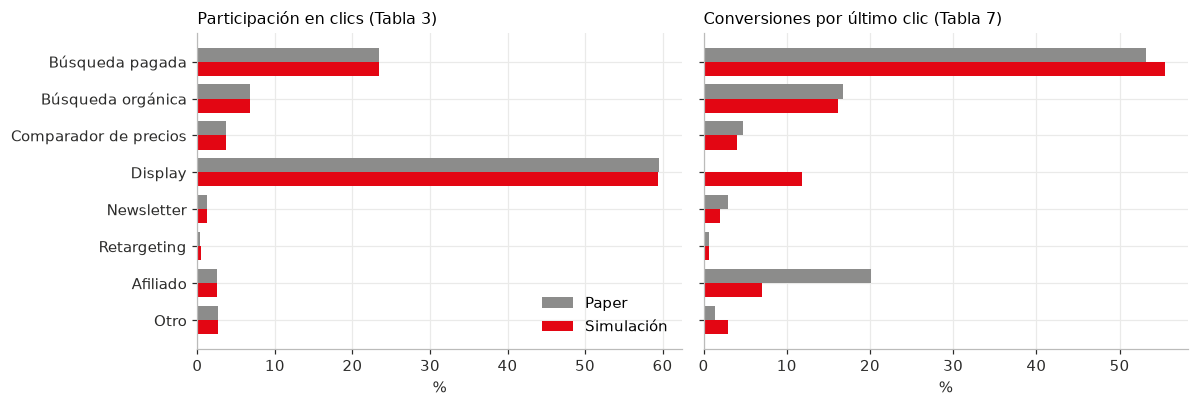

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
y = np.arange(len(P.CANALES)); h = 0.38
for ax, (col_p, col_s, titulo) in zip(axes, [('clics_paper_%', 'clics_sim_%', 'Participación en clics (Tabla 3)'),
                                             ('ultimo_clic_paper_%', 'ultimo_clic_sim_%', 'Conversiones por último clic (Tabla 7)')]):
    ax.barh(y - h/2, t3[col_p], h, color=GRIS, label='Paper')
    ax.barh(y + h/2, t3[col_s], h, color=ROJO, label='Simulación')
    ax.set_title(titulo, loc='left', fontsize=10.5); ax.set_xlabel('%')
axes[0].set_yticks(y, [P.NOMBRES[c] for c in P.CANALES]); axes[0].invert_yaxis()
axes[0].legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('../figures/validacion_simulacion.png', dpi=150); plt.show()

**Lectura.**
- **Tabla 1 y Tabla 3 se reproducen casi exactas:** recorridos, clics, proporción de recorridos largos, media y DE del largo, tasa de conversión y participación de cada canal en los clics. Esto era esperable: son los datos que se usaron para construir el simulador.
- **La Tabla 7 (último clic) NO se reproduce bien en dos canales.** En el paper casi ninguna compra termina en display (0,14 %) y una de cada cinco termina en afiliado (20 %); en la simulación, display cierra el 12 % y afiliado el 7 %.
- **Por qué:** el supuesto S1 sortea el canal de cada clic *independientemente de quién es la persona*. En la realidad no es así: quien ve muchos banners es otro tipo de usuario (poca intención) y los afiliados de DS1 son sitios de cupones que se visitan justo antes de pagar (el paper lo dice en la sección 6.1). Esa relación entre *tipo de persona* y *canal* no está en ninguna tabla del paper, así que el simulador no la tiene. Lo retomamos en la comparación (paso 6) porque explica la mayor diferencia de todo el ejercicio.

## 5. Recreación del análisis

### 5.1 El grafo de Markov

El modelo de Anderl et al. es un grafo $M = \langle S, W \rangle$: los nodos $S$ son los estados (INICIO, los canales, CONVERSIÓN y NULO) y las aristas $W$ son las probabilidades de pasar de un estado al siguiente, $w_{ij} = P(\text{siguiente} = j \mid \text{actual} = i)$. Las probabilidades se estiman contando: de todas las veces que alguien estuvo en $i$, qué fracción pasó a $j$. CONVERSIÓN y NULO son **absorbentes**: de ahí no se sale.

Antes de usar el grafo para atribuir, se dibuja. Primero el de orden 1 (nodo = canal), que se puede ver completo. Los de orden 2 a 4 tienen cientos de nodos, así que solo se muestra un pedazo del de orden 2 para ver qué cambia al darle memoria.

#### Grafo de orden 1 del DS1 simulado

Cómo leer la figura:
- **Tamaño del nodo:** participación del canal en los clics (Tabla 3). Display va al centro porque es el 59 % de los clics.
- **Color del nodo y "conv.":** probabilidad de pasar a CONVERSIÓN desde ese canal. Es la flecha roja hacia CONVERSIÓN.
- **↻:** probabilidad de que el clic siguiente sea por el mismo canal (*carryover*).
- **Grosor de las flechas:** probabilidad de transición. Entre canales solo se dibujan las de 5 % o más; la matriz de la derecha las muestra todas.

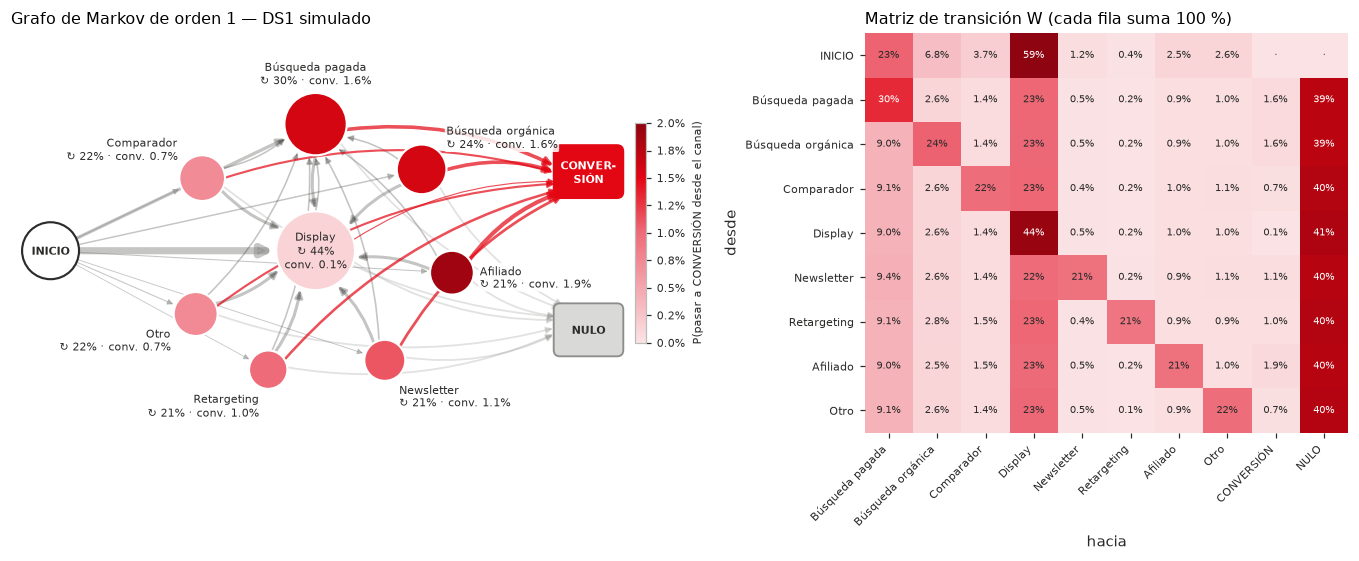

In [13]:
W1 = G.matriz_orden1(clics, recorridos)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.45, 1]})
G.dibujar_grafo_orden1(W1, axes[0], umbral=0.05, titulo='Grafo de Markov de orden 1 — DS1 simulado')
G.dibujar_matriz(W1, axes[1])
plt.tight_layout(); plt.savefig('../figures/grafo_orden1.png', dpi=150); plt.show()

**Lectura.**
- **Todas las filas de W se parecen**, salvo la diagonal: desde cualquier canal, el siguiente clic va a display cerca del 23 % de las veces y a búsqueda pagada cerca del 9 %; se repite el mismo canal entre 21 % y 30 % (display, 44 %); y el recorrido termina en alrededor del 40 %. Es el **supuesto S1 hecho visible**: en la simulación, a dónde se va después no depende de dónde se está (salvo repetir). En los datos reales del paper, W tendría estructura propia (por ejemplo, display → búsqueda), que el paper no publica.
- **Lo que sí distingue a los canales es la flecha a CONVERSIÓN:** afiliado (1,9 %), búsqueda pagada y orgánica (1,6 %) cierran más; display casi nunca cierra (0,1 %), aunque es el canal por el que más se pasa.
- Este grafo es justo el Markov de orden 1: solo mira el último nodo antes de salir. Por eso **predice igual que la regla del último clic** (Tabla 5, ambos 0,758).

#### Recorridos concretos de los datos sobre el grafo

Cada recorrido de la base es un camino en el grafo: sale de INICIO, pasa por sus canales en orden y termina en CONVERSIÓN o en NULO. La figura dibuja dos recorridos reales de la base simulada (uno con compra y uno sin compra) sobre el grafo de orden 1. El grafo de la sección anterior es la suma de los 600.978 caminos como estos.

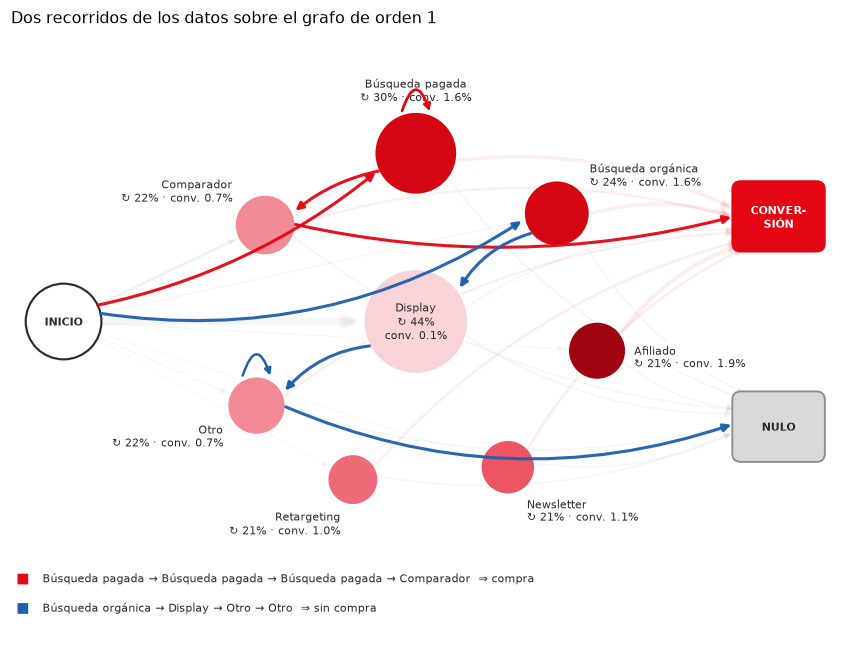

In [14]:
rr = recorridos.set_index('journey_id')
con_compra = rr[(rr.convierte == 1) & rr.largo.between(4, 5)].index[0]
sin_compra = rr[(rr.convierte == 0) & rr.largo.between(3, 4)].index[5]
fig, ax = plt.subplots(figsize=(9, 6))
G.dibujar_recorridos(W1, clics, recorridos, [con_compra, sin_compra], ax,
                     titulo='Dos recorridos de los datos sobre el grafo de orden 1')
plt.tight_layout(); plt.savefig('../figures/grafo_recorridos.png', dpi=150); plt.show()

**Lectura.** Las flechas de un mismo canal a sí mismo (el pequeño lazo) son clics repetidos por el mismo canal. Contar, para todos los recorridos, cuántas veces se usa cada flecha y dividir por las salidas de cada nodo da la matriz W.

#### Del orden 1 al orden 2: por qué la memoria ayuda

En el orden 2, el nodo deja de ser un canal y pasa a ser una **pareja** (canal anterior › canal actual). La figura toma el nodo búsqueda pagada del grafo de orden 1 y muestra en qué parejas se parte en el de orden 2, con la probabilidad de pasar a CONVERSIÓN de cada una (tasa directa, sin suavizar; solo parejas con 300 visitas o más).

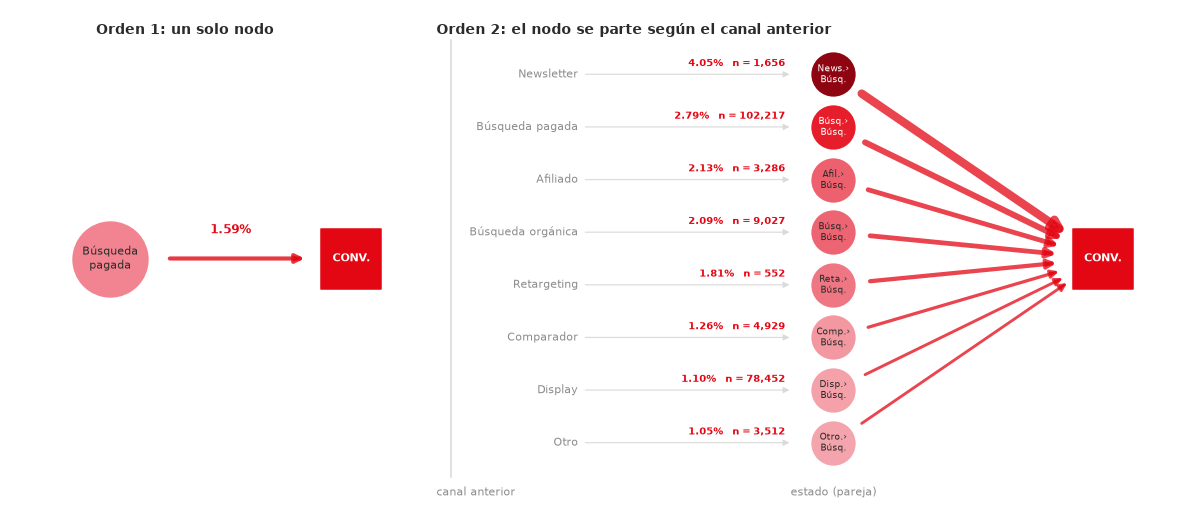

Orden 1, búsqueda pagada → CONVERSIÓN: 1.59%


,estado,desde,visitas,compras,p_conversion
0,Newsletter > SEA,Newsletter,1656,67,0.0405
1,SEA > SEA,SEA,102217,2852,0.0279
2,Affiliate > SEA,Affiliate,3286,70,0.0213
3,SEO > SEA,SEO,9027,189,0.0209
4,Retargeting > SEA,Retargeting,552,10,0.0181
5,PriceComp > SEA,PriceComp,4929,62,0.0126
6,Display > SEA,Display,78452,860,0.0110
7,Other > SEA,Other,3512,37,0.0105


In [15]:
t2, p_sea_orden1 = G.tasas_orden2(clics, recorridos, canal='SEA', min_visitas=300)
fig, ax = plt.subplots(figsize=(11, 4.8))
G.dibujar_detalle_orden2(t2, p_sea_orden1, canal='SEA', ax=ax)
plt.tight_layout(); plt.savefig('../figures/grafo_orden2_detalle.png', dpi=150); plt.show()
print(f'Orden 1, búsqueda pagada → CONVERSIÓN: {p_sea_orden1:.2%}')
t2

**Lectura.**
- En el orden 1, todo el que termina en búsqueda pagada recibe la misma probabilidad (1,6 %). En el orden 2, esa misma llegada **vale casi cuatro veces más o menos según de dónde viene**: de 1,1 % (desde display u otro) a 4,1 % (desde newsletter); repetir búsqueda pagada (SEA › SEA, el *carryover*) da 2,8 %.
- El orden 1 no puede ver esa diferencia y el orden 2 sí. **Esa es la razón del salto de AUC de 0,758 a 0,834** (sección 5.2) y del hallazgo central del paper: recordar el canal anterior mejora mucho la predicción.
- Display › SEA queda bajo aunque S3 premia esa pareja (+1,0 × 1,5): el clic de display resta casi lo mismo por sí solo (Tabla 8: −3,43 × 0,45). El efecto neto de la pareja queda cerca de cero.
- Retargeting › SEA tiene solo 552 visitas: su tasa es ruidosa. Con órdenes 3 y 4 casi todos los nodos son así; por eso el modelo suaviza hacia el orden inferior (`src/markov.py`).

#### El grafo de orden 2 completo

El detalle anterior es una sola columna del grafo de orden 2. Aquí está el grafo completo construido con los datos: 72 nodos (8 canales actuales × 9 posibilidades para el anterior, incluida "ninguno" en el primer clic). Cada nodo se ubica en una rejilla: **columna = canal actual, fila = canal anterior**. El tamaño es el número de visitas y el color, la probabilidad de pasar a CONVERSIÓN. Se dibujan las 45 transiciones más frecuentes; las demás existen pero no dejarían ver nada.

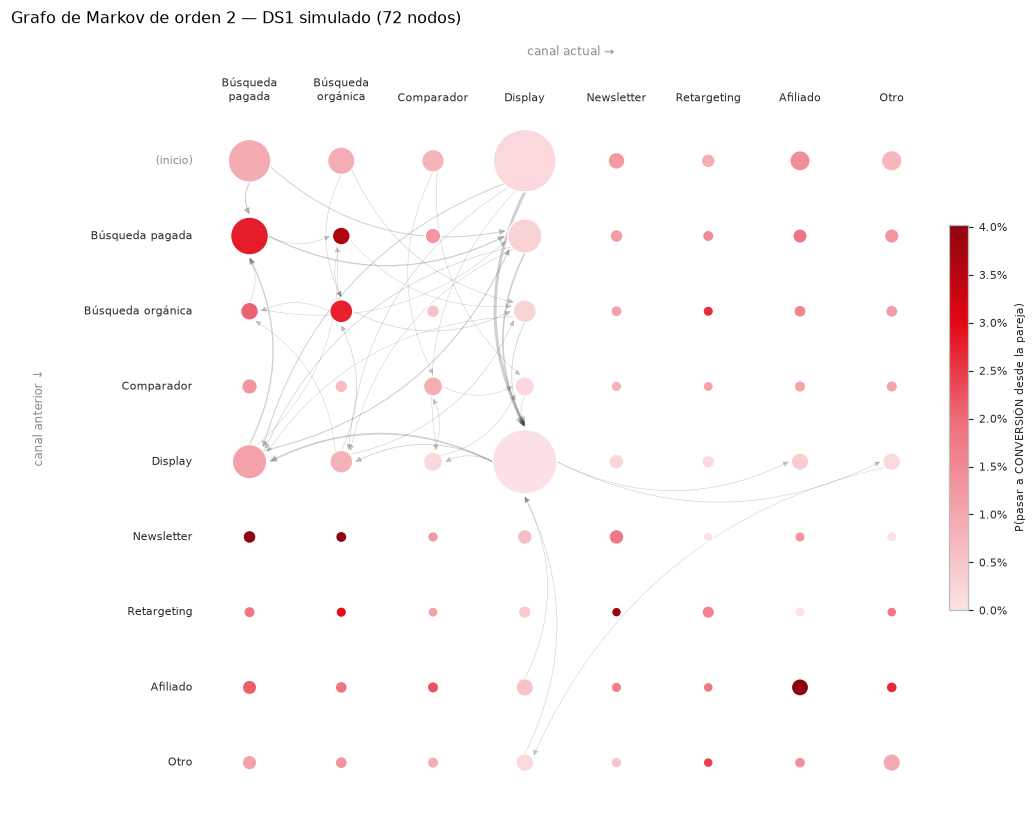

In [16]:
grafos = {k: G.grafo_datos(clics, recorridos, k) for k in (1, 2, 3, 4)}
fig, ax = plt.subplots(figsize=(11, 7.5))
G.dibujar_grafo_orden2(grafos[2], ax, top_aristas=45)
ax.set_title('Grafo de Markov de orden 2 — DS1 simulado (72 nodos)', loc='left', fontsize=10.5)
plt.tight_layout(); plt.savefig('../figures/grafo_orden2.png', dpi=150); plt.show()

**Lectura.**
- Una columna completa es un nodo del orden 1 partido según el canal anterior. Dentro de una misma columna el color cambia: es la información que el orden 1 no tiene.
- Las parejas más oscuras están en las filas de newsletter y de búsqueda (newsletter › búsqueda, búsqueda pagada › orgánica, afiliado › afiliado): son las secuencias que S3 premia, y el grafo las recupera de los datos.
- Las flechas solo pueden ir de la pareja (a › b) a una pareja (b › c): el canal actual de una pasa a ser el anterior de la siguiente. Por eso salen de una columna y llegan a la fila del mismo canal.

#### Qué le pasa al grafo cuando crece el orden

Con más memoria el grafo se multiplica: 8 nodos en el orden 1, 72 en el 2, 540 en el 3 y 2.926 en el 4. Los mismos 600.978 recorridos se reparten entre muchos más nodos, y cada uno se ve menos veces. La tabla y la figura lo muestran con los datos (en la figura, gris = nodo con menos de 50 visitas).

,orden,estados,aristas_entre_estados,visitas_mediana,% estados con < 50 visitas
0,1,8,64,46436,0.0000
1,2,72,532,1625,4.2000
2,3,540,2918,68,43.9000
3,4,2926,10056,8,77.6000


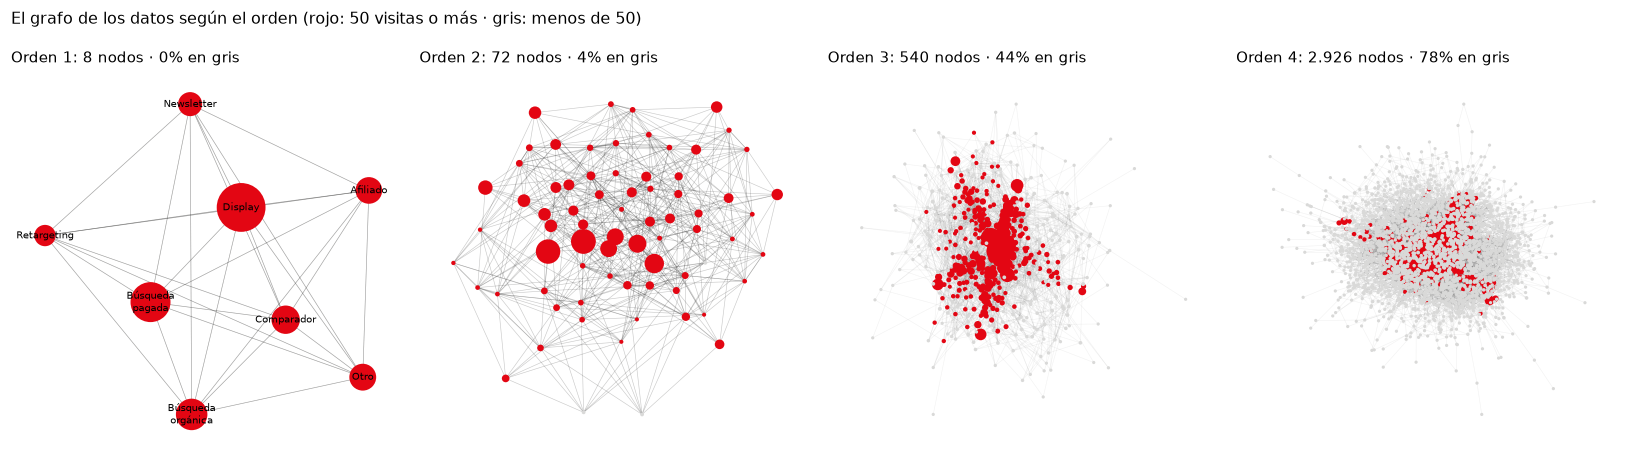

In [17]:
display(G.resumen_grafos(clics, recorridos).round(1))
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
G.dibujar_crecimiento(grafos, axes)
fig.suptitle('El grafo de los datos según el orden (rojo: 50 visitas o más · gris: menos de 50)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.savefig('../figures/grafo_por_orden.png', dpi=150); plt.show()

**Lectura.** En el orden 4, la mitad de los nodos se ve 8 veces o menos y el 78 % tiene menos de 50 visitas. Con tan pocas visitas, la tasa de conversión de cada nodo es casi puro ruido. Esto explica dos resultados: por qué el orden 4 no le gana al 3 (Tabla 5) y por qué, al bajar a 75.000 recorridos (paso 7), el orden 4 es el primero que cae. También justifica el suavizado hacia el orden inferior (`src/markov.py`).

#### El efecto de remoción, visto en el grafo

El efecto de remoción de un canal es cuánto cae la probabilidad de llegar de INICIO a CONVERSIÓN si ese canal desaparece. Para calcularlo, todo lo que entraba al canal se manda a NULO y se recalcula la probabilidad de absorción en CONVERSIÓN, resolviendo $(I - Q)\,x = r$ ($Q$: transiciones entre estados transitorios; $r$: probabilidad de pasar a CONVERSIÓN desde cada uno).

La figura lo muestra en el grafo de orden 1 para búsqueda pagada, el canal con más aporte.

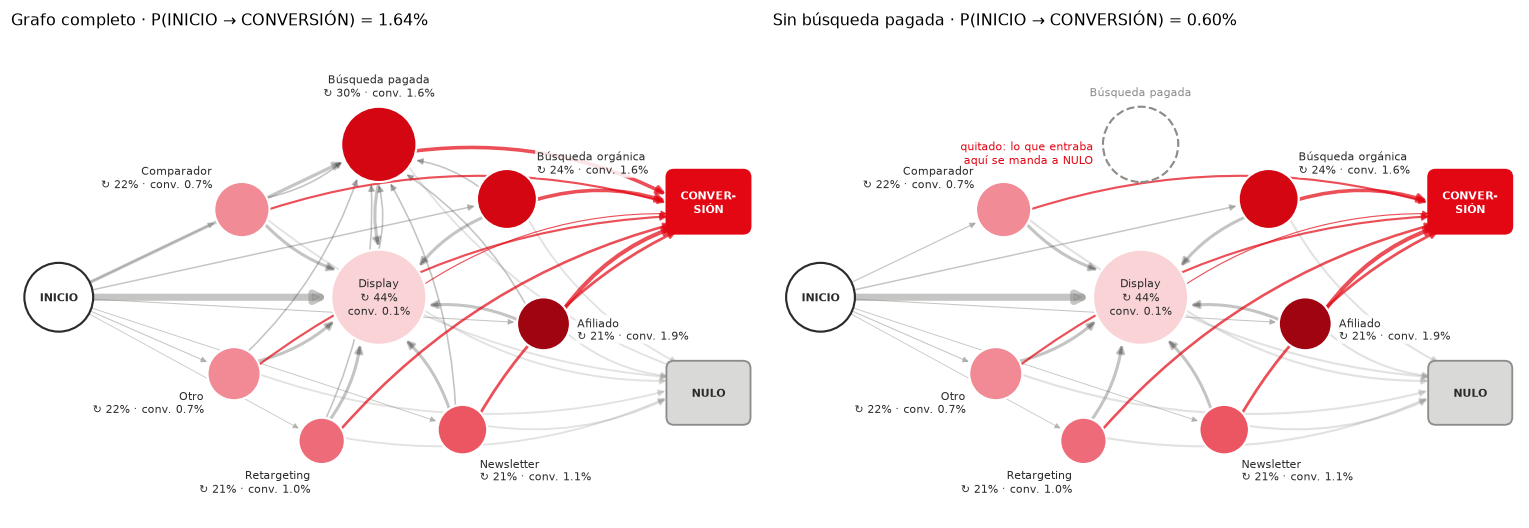

P(INICIO → CONVERSIÓN): 0.0164 con búsqueda pagada · 0.0060 sin ella · efecto de remoción 0.0104


,canal,p_con_canal,p_sin_canal,efecto_remocion,efecto_%
0,SEA,0.0164,0.0060,0.0104,41.3000
1,SEO,0.0164,0.0129,0.0035,13.8000
2,PriceComp,0.0164,0.0152,0.0012,4.7000
3,Display,0.0164,0.0093,0.0071,28.2000
4,Newsletter,0.0164,0.0159,0.0005,2.0000
5,Retargeting,0.0164,0.0162,0.0002,0.6000
6,Affiliate,0.0164,0.0149,0.0015,5.9000
7,Other,0.0164,0.0155,0.0009,3.4000


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
p_con, p_sin, efecto = G.dibujar_remocion(W1, 'SEA', axes)
plt.tight_layout(); plt.savefig('../figures/grafo_remocion.png', dpi=150); plt.show()
print(f'P(INICIO → CONVERSIÓN): {p_con:.4f} con búsqueda pagada · {p_sin:.4f} sin ella · efecto de remoción {efecto:.4f}')
G.remocion_por_canal(W1).round({'p_con_canal': 4, 'p_sin_canal': 4, 'efecto_remocion': 4, 'efecto_%': 1})

**Lectura.**
- Sin búsqueda pagada, la probabilidad de compra cae de 1,64 % a 0,60 %. Ese 1,04 % que se pierde es su efecto de remoción: el **41 %** de la suma de efectos de todos los canales.
- Display queda segundo (28 %), aunque casi nunca cierra: al quitarlo se pierden los recorridos que pasan por él antes de llegar a los canales que sí cierran. Es la diferencia entre *aparecer* en el recorrido y *aportar* a la compra, que el último clic no ve.
- Con el orden 1 el reparto ya se parece al del orden 3 de la tabla siguiente (búsqueda pagada 38,7 %, display 25,7 %, orgánica 14,8 %).

#### Efecto de remoción del orden 3 frente a la Tabla 7

Ahora se repite el cálculo con el modelo de orden 3, que es el que el paper usa para atribuir, y se compara con la columna "Markov graph (third order)" de la Tabla 7. `efecto_remocion` es la caída absoluta de P(INICIO → CONVERSIÓN); `sim_markov3_%` es su porcentaje sobre la suma.

*Simplificación declarada:* para el canal $c$ se quitan a la vez todos los estados que terminan en $c$; el paper promedia los efectos de esos estados uno por uno.

In [19]:
t7, p_base = comparar_tabla7(clics, recorridos, orden=3)
print(f'P(INICIO → CONVERSIÓN) en el grafo de orden 3: {p_base:.4f}')
t7.round({'paper_markov3_%': 2, 'sim_markov3_%': 2, 'efecto_remocion': 4})

P(INICIO → CONVERSIÓN) en el grafo de orden 3: 0.0164


,canal,paper_markov3_%,sim_markov3_%,efecto_remocion
0,SEA,46.2900,38.7400,0.0115
1,SEO,19.5400,14.8400,0.0044
2,PriceComp,5.2900,5.8200,0.0017
3,Display,0.9300,25.6800,0.0076
4,Newsletter,4.4700,2.8000,0.0008
5,Retargeting,1.2500,0.9000,0.0003
6,Affiliate,19.7100,6.9800,0.0021
7,Other,2.5200,4.2500,0.0013


**Lectura.**
- El grafo reproduce la tasa de conversión total (P(INICIO → CONVERSIÓN) = 1,64 %), como debe ser.
- El orden de importancia coincide en la parte alta (la búsqueda pagada es el canal con mayor aporte: 38,7 % frente a 46,3 % en el paper) y en los canales pequeños (comparador, newsletter, retargeting y otro quedan entre 1 % y 6 % en ambos).
- **Display es la gran diferencia:** 25,7 % en la simulación frente a 0,9 % en el paper. Es la consecuencia directa de lo visto en 4.4: en la simulación, display aparece en recorridos que compran; en la realidad, casi nunca.
- **Lección:** el efecto de remoción depende de *quién pasa por cada canal*, no solo de los conteos. Dos mecanismos distintos pueden dar el mismo AUC (ver paso 6) y atribuciones muy diferentes.

### 5.2 Capacidad predictiva: validación cruzada de 10 particiones (Tabla 5)

Mismo protocolo que el paper: 10 particiones estratificadas; en cada una se entrena con 9/10 y se evalúa dentro de muestra (con lo que entrenó) y fuera de muestra (la décima parte que no vio). Métricas: AUC y lift del decil superior.

*Decisión de implementación:* el Markov estima la probabilidad de compra de cada estado con un suavizado hacia el orden inferior (`src/markov.py`), para que los estados raros de orden 3–4 no den tasas absurdas por falta de datos.

*Ejecución:* las 10 particiones son independientes, así que se reparten entre los núcleos del equipo con `joblib` (`N_JOBS`). Cambia el tiempo, no el resultado.

In [20]:
res = validacion_cruzada(clics, recorridos, k_folds=K_FOLDS, verbose=False, n_jobs=N_JOBS)
res.to_csv('../results/cv_ds1.csv', index=False)
tabla = tabla_comparacion(res)
tabla.to_csv('../results/tabla5_comparacion.csv')
tabla.round(3)

,paper_auc_fuera,auc_mean_fuera,auc_std_fuera,paper_lift_fuera,lift_mean_fuera,lift_std_fuera,paper_auc_dentro,auc_mean_dentro
Markov orden 1,0.7400,0.7580,0.0060,2.9080,2.4370,0.1390,0.7400,0.7600
Markov orden 2,0.8210,0.8340,0.0060,4.6940,5.3730,0.1700,0.8210,0.8370
Markov orden 3,0.8300,0.8320,0.0070,5.2390,5.6810,0.2040,0.8320,0.8390
Markov orden 4,0.8290,0.8320,0.0070,5.2910,5.7080,0.1580,0.8360,0.8520
Último clic,0.7410,0.7580,0.0060,2.9180,2.4370,0.1390,0.7400,0.7600
Primer clic,0.7140,0.7180,0.0070,2.4300,2.2910,0.1130,0.7130,0.7180
Logit 1,0.8180,0.8320,0.0050,4.9260,5.7460,0.1700,0.8180,0.8320
Logit 2,0.8270,0.8510,0.0050,5.1860,6.1420,0.1620,0.8280,0.8510


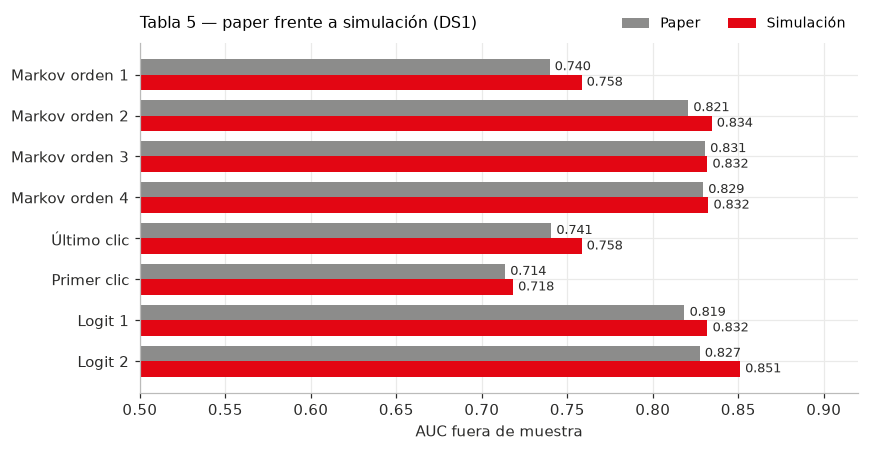

In [21]:
orden = list(P.RESULTADOS_PAPER_DS1)
y = np.arange(len(orden)); h = 0.38
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(y - h/2, tabla.loc[orden, 'paper_auc_fuera'], h, color=GRIS, label='Paper')
ax.barh(y + h/2, tabla.loc[orden, 'auc_mean_fuera'], h, color=ROJO, label='Simulación')
for i, m in enumerate(orden):
    ax.text(tabla.loc[m, 'auc_mean_fuera'] + 0.003, i + h/2, f"{tabla.loc[m, 'auc_mean_fuera']:.3f}", va='center', fontsize=8.5, color=TINTA)
    ax.text(tabla.loc[m, 'paper_auc_fuera'] + 0.003, i - h/2, f"{tabla.loc[m, 'paper_auc_fuera']:.3f}", va='center', fontsize=8.5, color=TINTA)
ax.set_yticks(y, orden); ax.invert_yaxis(); ax.set_xlim(0.5, 0.92)
ax.set_xlabel('AUC fuera de muestra'); ax.set_title('Tabla 5 — paper frente a simulación (DS1)', loc='left', fontsize=10.5, pad=10)
ax.legend(frameon=False, ncol=2, loc='lower right', bbox_to_anchor=(1, 1.0), fontsize=9)
plt.tight_layout(); plt.savefig('../figures/auc_paper_vs_simulado.png', dpi=150); plt.show()

## 6. Comparación con el paper

### Lo que sí se recrea

| Hallazgo del paper (Tabla 5) | Paper | Simulación | ¿Se recrea? |
|---|---|---|---|
| El Markov de orden 1 es idéntico al último clic | 0,740 = 0,741 | 0,758 = 0,758 | ✅ Exacto |
| El primer clic es el peor modelo | 0,714 | 0,718 | ✅ |
| Gran salto al dar memoria (orden 1 → 2) | +0,081 | +0,076 | ✅ |
| Después del orden 2 la ganancia es pequeña | 0,821 → 0,830 → 0,829 | 0,834 → 0,832 → 0,832 | ✅ Meseta (en la simulación, plana) |
| Los modelos que recuerdan el orden superan a las reglas de un clic | sí | sí | ✅ |
| La brecha dentro/fuera de muestra crece con el orden (sobreajuste) | orden 4: 0,836 → 0,829 | orden 4: 0,852 → 0,832 | ✅ Más marcada en la simulación |
| Variabilidad entre particiones | DE ≈ 0,006–0,009 | DE ≈ 0,005–0,007 | ✅ |

Markov 1 y 4, Logit 2 y todos los lift **no** se usaron para calibrar, así que su parecido con el paper sí cuenta como evidencia.

### Lo que difiere y por qué

1. **El Logit 2 gana con más ventaja en la simulación** (0,851 frente a 0,827). El mecanismo simulado (S3) *es* un logit sobre conteos y sobre los últimos canales, que es casi exactamente la forma del Logit 2. El modelo "conoce" la forma de los datos. En la realidad, el mecanismo no tiene por qué ser un logit y la ventaja se diluye.
2. **Los lift de los modelos con memoria son más altos** (5,4–6,1 frente a 4,7–5,3) y los de las reglas de un clic más bajos (2,4 frente a 2,9). La simulación concentra la compra en recorridos más fáciles de identificar; los datos reales tienen ruido que el simulador no incluye (personas que compran sin señal previa, cookies borradas, varios dispositivos).
3. **La atribución por canal (Tabla 7) no coincide en display y afiliado**, aunque los AUC sí coinciden. El paper no publica cómo se relaciona el tipo de persona con el canal que usa, y sin eso la simulación no puede repartir bien el crédito.

**Conclusión del paso 6:** se recrea bien el *comportamiento predictivo* (qué modelo gana y por cuánto). No se recrea la *atribución por canal*. Y esa diferencia enseña algo útil: que un modelo prediga bien no garantiza que reparta bien el crédito entre canales.

### 6.1 ¿Se recuperan los coeficientes de la Tabla 8?

Se ajusta el Logit 1 sin regularización sobre los datos simulados. Si el mecanismo fuera solo conteos, debería recuperar los coeficientes de la Tabla 8 (escalados por $a$). Como también hay recencia, secuencia y volver, el Logit 1 absorbe parte de esos efectos en los conteos.

In [22]:
t8 = comparar_tabla8(clics, recorridos)
t8.round(3)

,canal,paper_beta,sim_beta
0,SEA,0.4430,0.8570
1,SEO,0.3880,0.7950
2,PriceComp,0.0020,0.3460
3,Display,-3.4270,-1.1460
4,Newsletter,0.6160,0.7880
5,Retargeting,0.3100,0.2860
6,Affiliate,1.1520,1.0730
7,Other,0.0320,0.3660
8,Intercepto,-4.5050,-4.4390


**Lectura.** Se recuperan **todos los signos** y el intercepto casi exacto (−4,44 frente a −4,51). Los coeficientes de búsqueda (SEA, SEO) salen más altos y el de display menos negativo que en el paper: el Logit 1 está absorbiendo en los conteos los efectos de secuencia y de volver, que el modelo no ve. Es la misma razón por la que en el paper el Logit 2 (con orden) le gana al Logit 1.

## 7. Extensión: ¿qué pasa con menos personas?

**Condición que se cambia (una sola):** el número de recorridos, es decir, de **personas**. Todo lo demás queda igual: mismos canales, mismo largo de los recorridos (2,41 clics por persona en promedio), mismo mecanismo y misma tasa de compra (1,64 %).

**Por qué esta condición:** DS1 tiene 600.978 personas. La escuela tiene del orden de **15.000 a 20.000 personas individualizadas** (leads) en su base, que no son lo mismo que 75.000 acciones: cada persona tiene varias interacciones. La pregunta práctica es si, con ese número de personas, darle memoria al modelo (órdenes 2 a 4) sigue ayudando o empieza a sobreajustar.

Se repite la validación cruzada completa (10 particiones) con 600.978, 150.000, 75.000, 20.000 y 15.000 personas.

In [23]:
tamanos = [600_978, 150_000, 75_000, 20_000, 15_000]
ext = extension_tamano(tamanos, k_folds=K_FOLDS, n_jobs=N_JOBS)
ext.to_csv('../results/extension_tamano.csv', index=False)
ext.pivot(index='modelo', columns='n_recorridos', values='auc')[tamanos[::-1]].round(3)

n = 600,978 listo (1,471,462 clics, 9,846 compras)
n = 150,000 listo (364,339 clics, 2,452 compras)
n = 75,000 listo (180,527 clics, 1,250 compras)
n = 20,000 listo (48,142 clics, 331 compras)
n = 15,000 listo (37,294 clics, 234 compras)


n_recorridos,15000,20000,75000,150000,600978
modelo,,,,,
Logit 1,0.8380,0.8380,0.8400,0.8270,0.8320
Logit 2,0.8650,0.8510,0.8560,0.8500,0.8510
Markov orden 1,0.7730,0.7610,0.7630,0.7580,0.7580
Markov orden 2,0.8390,0.8250,0.8230,0.8350,0.8340
Markov orden 3,0.8320,0.8090,0.8210,0.8230,0.8320
Markov orden 4,0.8200,0.7920,0.8140,0.8180,0.8320
Primer clic,0.7050,0.7240,0.7290,0.7070,0.7180
Último clic,0.7700,0.7660,0.7620,0.7580,0.7580


In [24]:
# Cuántas acciones y compras hay en cada tamaño, y cuánto varía el AUC entre particiones (DE)
volumen = ext.groupby('n_recorridos')[['clics', 'conversiones']].first().sort_index(ascending=False)
volumen['clics por persona'] = volumen.clics / volumen.index
display(volumen.round(2))
ext.pivot(index='modelo', columns='n_recorridos', values='auc_de')[tamanos[::-1]].round(3)

,clics,conversiones,clics por persona
n_recorridos,,,
600978,1471462,9846,2.4500
150000,364339,2452,2.4300
75000,180527,1250,2.4100
20000,48142,331,2.4100
15000,37294,234,2.4900


n_recorridos,15000,20000,75000,150000,600978
modelo,,,,,
Logit 1,0.0420,0.0370,0.0120,0.0150,0.0050
Logit 2,0.0360,0.0370,0.0160,0.0110,0.0050
Markov orden 1,0.0250,0.0330,0.0160,0.0070,0.0060
Markov orden 2,0.0240,0.0500,0.0170,0.0120,0.0060
Markov orden 3,0.0350,0.0520,0.0180,0.0120,0.0070
Markov orden 4,0.0310,0.0480,0.0180,0.0160,0.0070
Primer clic,0.0350,0.0330,0.0170,0.0180,0.0070
Último clic,0.0260,0.0300,0.0160,0.0070,0.0060


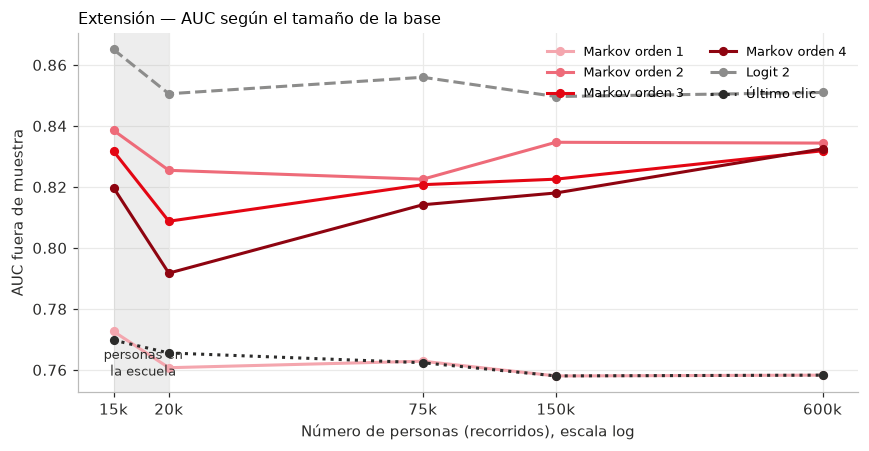

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.2))
estilos = {'Markov orden 1': ('#F4A6AE', '-'), 'Markov orden 2': ('#EE6B79', '-'),
           'Markov orden 3': ('#E30613', '-'), 'Markov orden 4': ('#8E0410', '-'),
           'Logit 2': (GRIS, '--'), 'Último clic': (TINTA, ':')}
for m, (col, ls) in estilos.items():
    d = ext[ext.modelo == m].sort_values('n_recorridos')
    ax.plot(d.n_recorridos, d.auc, ls, color=col, lw=2, marker='o', ms=5, label=m)
ax.set_xscale('log'); ax.set_xticks(tamanos, [f'{t//1000}k' for t in tamanos]); ax.minorticks_off()
ax.axvspan(15_000, 20_000, color=GRIS, alpha=0.15, lw=0)
ax.text(17_500, ax.get_ylim()[0] + 0.004, 'personas en\nla escuela', va='bottom', ha='center', fontsize=8.5, color=TINTA)
ax.set_xlabel('Número de personas (recorridos), escala log'); ax.set_ylabel('AUC fuera de muestra')
ax.set_title('Extensión — AUC según el tamaño de la base', loc='left', fontsize=10.5)
ax.legend(frameon=False, ncol=2, fontsize=8.5)
plt.tight_layout(); plt.savefig('../figures/extension_tamano.png', dpi=150); plt.show()

**Lectura.**

| Personas (recorridos) | Acciones (clics) | Compras | Mejor Markov | Orden 4 | DE entre particiones |
|---|---|---|---|---|---|
| 600.978 | 1.471.462 | 9.846 | 2, 3 y 4 empatan (0,832–0,834) | 0,832 | 0,006 |
| 150.000 | 364.339 | 2.452 | 2 (0,835) | 0,818 | 0,012 |
| 75.000 | 180.527 | 1.250 | 2 (0,823) | 0,814 | 0,017 |
| **20.000** | **48.142** | **331** | **2 (0,825)** | **0,792** | **0,050** |
| 15.000 | 37.294 | 234 | 2 (0,839) | 0,820 | 0,024–0,035 |

1. **Con menos personas, más memoria deja de ayudar.** Con la base completa, los órdenes 2, 3 y 4 empatan. Al reducirla, el orden 4 cae primero: tiene miles de estados y cada uno se ve pocas veces (ver "Qué le pasa al grafo cuando crece el orden").
2. **A la escala de la escuela (15.000–20.000 personas), el orden 2 es el mejor Markov y el Logit 2 sigue arriba (0,85–0,87).**
3. **Con tan pocas compras, el ruido es del mismo tamaño que las diferencias.** A 20.000 personas hay 331 compras y el AUC varía ±0,05 entre particiones; por eso 15.000 sale "mejor" que 20.000. Comparar modelos a esa escala exige repetir la validación y mirar la DE, no un solo número.
4. **El orden 1 y el último clic siguen siendo idénticos** en todos los tamaños.

**Matiz:** se mantuvo la tasa de compra del paper (1,64 %). La escuela convierte cerca de 8 de cada 100 leads, así que con 20.000 personas tendría unas 1.600 matrículas y no 331. El escenario es conservador.

### 7.2 Análisis adicional: menos personas, pero con más acciones cada una

La extensión cambió una sola condición, como pide la guía. Pero en la escuela una persona no hace 2,4 interacciones en promedio: tiene varias (formulario, correos, eventos, contacto comercial). Por eso se agrega un análisis aparte, declarado como tal: **20.000 personas con al menos 3 acciones cada una**. Las que tenían 1 o 2 clics pasan a tener 3; las demás quedan igual.

Eso da unas 77.000 acciones para 20.000 personas (3,9 por persona), el orden de magnitud de la escuela. Todo lo demás se mantiene: mecanismo, tasa de compra y 10 particiones.

In [26]:
largos3 = extension_tamano([20_000], k_folds=K_FOLDS, n_jobs=N_JOBS, largo_minimo=3)
largos3.to_csv('../results/extension_20k_largo3.csv', index=False)
base20 = ext[ext.n_recorridos == 20_000].set_index('modelo')
comp = pd.DataFrame({
    'AUC 20k (2,4 acciones por persona)': base20.auc,
    'DE': base20.auc_de,
    'AUC 20k (≥ 3 acciones por persona)': largos3.set_index('modelo').auc,
    'DE ': largos3.set_index('modelo').auc_de,
}).loc[list(P.RESULTADOS_PAPER_DS1)]
print(f"Acciones: {int(base20.clics.iloc[0]):,} frente a {int(largos3.clics.iloc[0]):,} · compras: {int(base20.conversiones.iloc[0])} frente a {int(largos3.conversiones.iloc[0])}")
comp.round(3)

n = 20,000 listo (77,307 clics, 334 compras)
Acciones: 48,142 frente a 77,307 · compras: 331 frente a 334


,"AUC 20k (2,4 acciones por persona)",DE,AUC 20k (≥ 3 acciones por persona),DE
modelo,,,,
Markov orden 1,0.7610,0.0330,0.7900,0.0290
Markov orden 2,0.8250,0.0500,0.8310,0.0300
Markov orden 3,0.8090,0.0520,0.8530,0.0340
Markov orden 4,0.7920,0.0480,0.8450,0.0350
Último clic,0.7660,0.0300,0.7900,0.0290
Primer clic,0.7240,0.0330,0.7200,0.0160
Logit 1,0.8380,0.0370,0.8680,0.0260
Logit 2,0.8510,0.0370,0.8720,0.0250


**Lectura.**
- **Con más acciones por persona, todos los modelos mejoran,** aunque el número de personas y de compras es el mismo (20.000 y ~330). El último clic pasa de 0,766 a 0,790 y el Logit 2, de 0,851 a 0,872.
- **El orden 3 vuelve a ganarle al 2** (0,853 frente a 0,831). Con recorridos más largos hay más secuencias que recordar y cada estado de orden 3 se ve más veces.
- **Para la tesis:** lo que limita al modelo no es solo cuántas personas hay, sino cuánta historia tiene cada una. Registrar todas las interacciones de cada lead (eventos, correos, contacto comercial, con su fecha) vale tanto como tener más leads.
- La DE sigue siendo de ±0,03, así que la ventaja del orden 3 sobre el 2 (0,022) es indicativa, no concluyente.

## 8. Conclusión

### Qué se pudo recrear

- **Los datos:** la simulación reproduce las cifras descriptivas de las Tablas 1 y 3 y la tasa de conversión.
- **El método:** grafo de Markov de orden 1 a 4 con INICIO, CONVERSIÓN y NULO (dibujado en la sección 5.1); efecto de remoción; los mismos seis modelos de comparación; validación cruzada de 10 particiones; AUC y lift.
- **Los hallazgos predictivos de la Tabla 5:** orden 1 = último clic; gran salto al recordar el canal anterior; meseta después del orden 2; los modelos con orden superan a las reglas de un clic; el sobreajuste crece con el orden.

### Qué no se pudo recrear

- **La atribución por canal (Tabla 7)**, sobre todo en display y afiliado. Falta un dato que el paper no publica: la relación entre el tipo de persona y el canal que usa.
- **La ventaja pequeña del Logit 2:** en la simulación es mayor, porque el mecanismo simulado tiene forma de logit.
- **El nivel exacto de los lift.**

Para generar las compras hubo que suponer el mecanismo (S3) y calibrarlo con cinco AUC del propio paper. Por eso esos cinco valores no prueban nada; la evidencia está en los modelos que no se usaron para calibrar.

### Qué deja para el trabajo de grado

1. **El enfoque se traslada directo.** Canal → touchpoint (pauta, orgánico, formulario, evento, LS, IL); compra → inicio de programa; INICIO, CONVERSIÓN y NULO → primer contacto, matrícula y "no se matriculó en el horizonte". El efecto de remoción responde una pregunta que hoy la escuela no puede responder: *¿cuánto aporta cada experiencia a la matrícula?* Eso es distinto de *¿en qué porcentaje de recorridos aparece?*
2. **Lo que los autores dejaron pendiente es el aporte de la tesis.**
   - **El tiempo entre contactos:** el paper usa solo el orden. Los autores lo dicen textualmente como extensión.
   - **Canales fuera de línea:** eventos, LS, IL y masterclasses.
   - **Ciclos largos:** años, no 30 días.
   - **Recompra:** el valor de vida del cliente que ellos no consideran; en la escuela, los egresados que vuelven.
3. **Con el volumen de la escuela, importa tanto cuántas personas como cuánta historia tiene cada una.** Con 15.000–20.000 personas y la historia corta del paper, el orden 2 basta y el orden 4 sobreajusta. Con 20.000 personas y al menos 3 acciones cada una, todos los modelos mejoran y el orden 3 vuelve a ganar (7.2). La tesis debe:
   - comparar siempre contra un modelo base fuerte (Logit 2 o LightGBM);
   - suavizar los estados raros;
   - preferir modelos que compartan información entre estados, como las redes sobre grafos temporales, en lugar de multiplicar estados.
4. **Predecir bien no es atribuir bien.** Se puede igualar el AUC del paper con un mecanismo que reparte el crédito de forma muy distinta. En la tesis, el puntaje de madurez (predicción) y la contribución de cada experiencia (atribución) deben validarse por separado. La segunda no debe presentarse como causal: el problema es endógeno, como advierten los autores.
5. **Los datos importan más que el modelo.** Para el grafo de la escuela hace falta:
   - fecha y hora por interacción;
   - separar experiencias gratuitas (estados transitorios) de programas pagados (estado absorbente);
   - corregir el sesgo de los correos sin UTM, que hoy se cuentan como tráfico orgánico.

### El grafo trasladado a la escuela

El esquema muestra cómo se vería el mismo grafo con los datos de la escuela. **Es ilustrativo:** no tiene probabilidades porque todavía no hay datos, y las flechas son solo ejemplos de caminos posibles. Lo que fija es la estructura: los touchpoints digitales y las experiencias gratuitas (eventos, masterclasses, LS, IL) y el contacto comercial son estados **transitorios**; el inicio de un programa pagado (MATRÍCULA) y el NULO (no se matriculó en el horizonte) son los **absorbentes**. Con datos, el efecto de remoción respondería cuánto aporta cada experiencia a la matrícula.

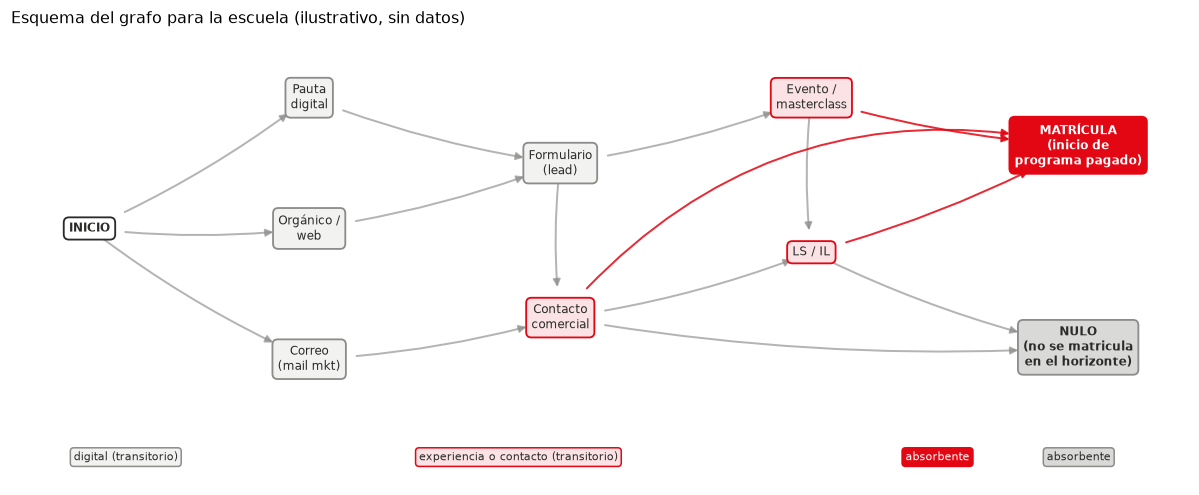

In [27]:
fig, ax = plt.subplots(figsize=(11, 4.6))
G.dibujar_grafo_escuela(ax)
ax.set_title('Esquema del grafo para la escuela (ilustrativo, sin datos)', loc='left', fontsize=10.5)
plt.tight_layout(); plt.savefig('../figures/grafo_escuela.png', dpi=150); plt.show()